# Regression Losses

For a residual $r = \hat y - y$ the regression losses differ in how strongly they punish large residuals, and therefore in how much a few outliers can pull a fit:

| Function | Per-element value | Gradient for large $|r|$ |
|---|---|---|
| `squared_error(pred, target)` | $r^2$ | grows like $2r$ |
| `l2_loss(pred, target)` | $\tfrac12 r^2$ (optax convention) | grows like $r$ |
| `absolute_error(pred, target)`, `l1_loss` | $|r|$ | constant $\pm 1$ |
| `huber_loss(pred, target, delta)` | $\tfrac12 r^2$ if $|r| \le \delta$, else $\delta(|r| - \tfrac12\delta)$ | constant $\pm\delta$ |
| `log_cosh(pred, target)` | $\log\cosh r$ | approaches $\pm 1$ |

All of them also accept `axis` and `reduction` (`'none'`, `'mean'`, `'sum'`). **The default reduction is not the same for every function**, so pass it explicitly when it matters (see Section 2).

## 1. Setup

In [1]:
import inspect

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

import braintools.metric as bm

## 2. Reductions and Defaults

With `reduction='none'` you get one value per element; `'mean'` and `'sum'` reduce over `axis` (all elements when `axis=None`). The defaults differ:

In [2]:
for name in ["squared_error", "l2_loss", "absolute_error", "l1_loss", "huber_loss", "log_cosh"]:
    default = inspect.signature(getattr(bm, name)).parameters["reduction"].default
    print(f"{name:15s} reduction default = {default!r}")

pred = jnp.array([[1.0, 2.0, 3.0], [2.0, 2.5, 2.0]])
target = jnp.array([[1.1, 1.9, 3.2], [2.0, 2.0, 2.0]])
print("squared_error, none:\n", np.round(np.asarray(bm.squared_error(pred, target)), 4))
print("squared_error, mean, axis=-1:", bm.squared_error(pred, target, axis=-1, reduction="mean"))
print("l2_loss default (none) == 0.5 * squared_error:", bool(jnp.allclose(bm.l2_loss(pred, target), 0.5 * bm.squared_error(pred, target))))
print("l1_loss default (mean):", bm.l1_loss(pred, target), "== mean |r|:", jnp.mean(jnp.abs(pred - target)))

squared_error   reduction default = 'none'
l2_loss         reduction default = 'none'
absolute_error  reduction default = 'mean'
l1_loss         reduction default = 'mean'
huber_loss      reduction default = 'none'
log_cosh        reduction default = 'none'
squared_error, none:
 [[0.01 0.01 0.04]
 [0.   0.25 0.  ]]
squared_error, mean, axis=-1: [0.02000001 0.08333334]
l2_loss default (none) == 0.5 * squared_error: True
l1_loss default (mean): 0.15000002 == mean |r|: 0.15000002


The element-wise values match optax:

In [3]:
r_pred, r_tgt = jax.random.normal(jax.random.PRNGKey(0), (2, 50))
checks = {
    "squared_error": (bm.squared_error(r_pred, r_tgt), optax.squared_error(r_pred, r_tgt)),
    "l2_loss": (bm.l2_loss(r_pred, r_tgt), optax.l2_loss(r_pred, r_tgt)),
    "huber_loss": (bm.huber_loss(r_pred, r_tgt, delta=0.5), optax.huber_loss(r_pred, r_tgt, delta=0.5)),
    "log_cosh": (bm.log_cosh(r_pred, r_tgt), optax.log_cosh(r_pred, r_tgt)),
}
for name, (ours, ref) in checks.items():
    print(f"{name:14s} max |difference| from optax: {float(jnp.max(jnp.abs(ours - ref))):.1e}")

squared_error  max |difference| from optax: 0.0e+00
l2_loss        max |difference| from optax: 0.0e+00
huber_loss     max |difference| from optax: 0.0e+00
log_cosh       max |difference| from optax: 0.0e+00


## 3. Loss Shape and Influence

The **gradient** with respect to the residual is the influence a data point has on the fit. Bounded gradients (L1, Huber, log-cosh) cap the influence of outliers; the L2 gradient keeps growing.

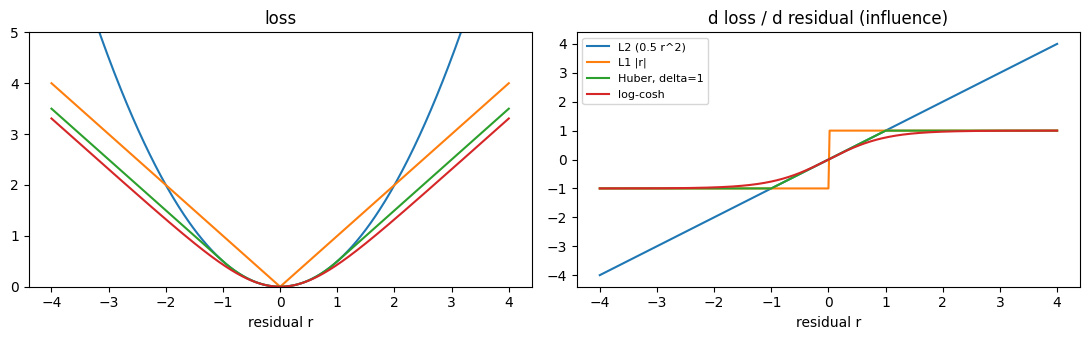

In [4]:
r = jnp.linspace(-4, 4, 401)
zero = jnp.zeros_like(r)
losses = {
    "L2 (0.5 r^2)": lambda r: bm.l2_loss(r, jnp.zeros_like(r)),
    "L1 |r|": lambda r: bm.absolute_error(r, jnp.zeros_like(r), reduction="none"),
    "Huber, delta=1": lambda r: bm.huber_loss(r, jnp.zeros_like(r), delta=1.0),
    "log-cosh": lambda r: bm.log_cosh(r, jnp.zeros_like(r)),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, f in losses.items():
    axes[0].plot(r, f(r), label=name)
    axes[1].plot(r, jax.vmap(jax.grad(lambda x: f(x[None])[0]))(r), label=name)
axes[0].set_title("loss")
axes[1].set_title("d loss / d residual (influence)")
axes[0].set_ylim(0, 5)
for ax in axes:
    ax.set_xlabel("residual r")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. Fitting With Outliers

A line is fitted by gradient descent to data in which 10 % of the points are corrupted. Minimizing L2 is pulled toward the outliers; the robust losses recover the true line much more closely.

true: slope 2.00, intercept 1.00
L2                 slope 2.02, intercept 1.45
L1                 slope 1.98, intercept 1.01
Huber (delta=0.2)  slope 1.99, intercept 1.03
log-cosh           slope 2.01, intercept 1.11


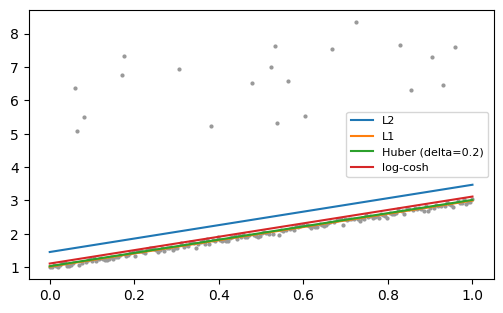

In [5]:
rng = np.random.default_rng(0)
x = np.linspace(0, 1, 200)
y = 2.0 * x + 1.0 + 0.05 * rng.normal(size=200)
bad = rng.choice(200, 20, replace=False)
y[bad] += rng.uniform(3, 6, 20)
x, y = jnp.asarray(x), jnp.asarray(y)


def fit(loss):
    def objective(p):
        return jnp.mean(loss(p[0] * x + p[1], y))
    step = jax.jit(jax.grad(objective))
    p = jnp.zeros(2)
    for _ in range(4000):
        p = p - 0.1 * step(p)
    return p


fits = {
    "L2": fit(lambda a, b: bm.l2_loss(a, b)),
    "L1": fit(lambda a, b: bm.absolute_error(a, b, reduction="none")),
    "Huber (delta=0.2)": fit(lambda a, b: bm.huber_loss(a, b, delta=0.2)),
    "log-cosh": fit(lambda a, b: bm.log_cosh(a, b)),
}
print("true: slope 2.00, intercept 1.00")
for name, (slope, intercept) in fits.items():
    print(f"{name:18s} slope {float(slope):.2f}, intercept {float(intercept):.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x, y, ".", color="0.6", ms=4)
for name, (slope, intercept) in fits.items():
    ax.plot(x, slope * x + intercept, label=name)
ax.legend(fontsize=8)
plt.show()

L2 estimates the conditional **mean**, so the outliers shift the intercept up; L1 estimates the **median** and ignores them almost completely. Huber and log-cosh sit in between: quadratic (efficient) for small residuals, linear (robust) for large ones. Pick Huber's `delta` around the scale of the ordinary noise.

## Summary

- `l2_loss` is half the squared error; `squared_error` is the full square.
- Reduction defaults differ between functions: pass `reduction=` explicitly.
- Robust losses bound the gradient of large residuals; use them when outliers are present.
- For comparing directions of vectors (cosine distance and similarity), see the pairwise-similarity tutorial.